# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "sofia", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

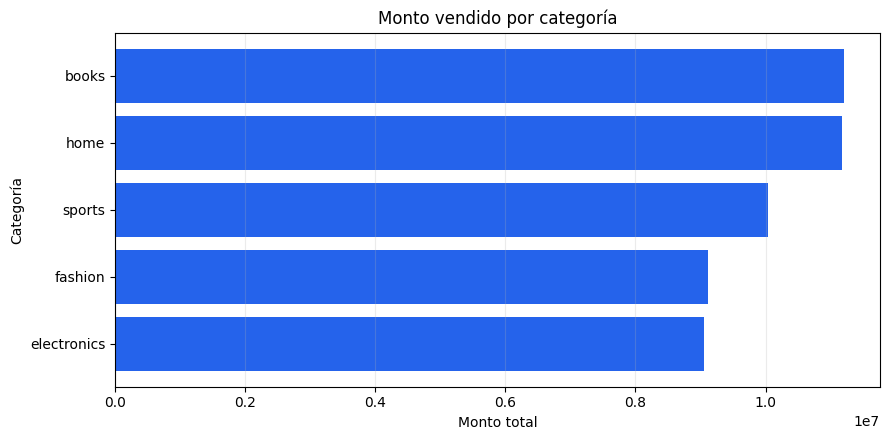

Respuesta: books es la categoría con mayor monto vendido (11,200,351.03).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

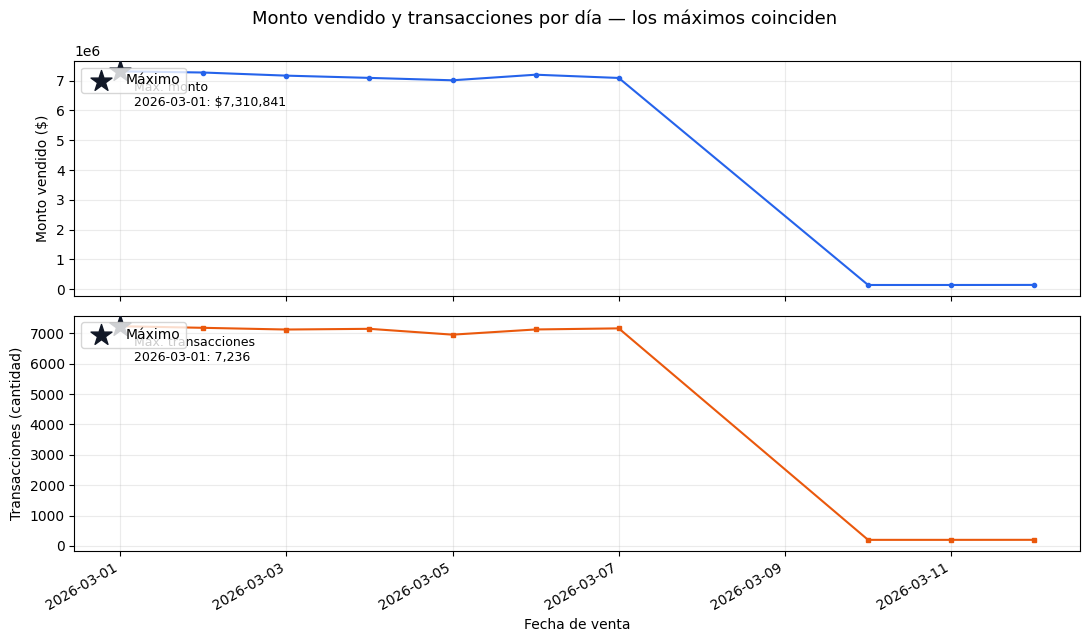

Respuesta: el día de mayor monto vendido fue 2026-03-01 ($7,310,840.77) y también fue el de más transacciones (7,236). Su ticket promedio fue $1,010.34, frente a $1,000.54 del período, así que el pico se explica sobre todo por la cantidad de compras más que por un ticket más alto.


In [0]:
# (1) Transformación con Spark: de fecha × país × categoría × canal a una fila por día
daily_sales = (spark.table(daily)
    .groupBy("sale_date")
    .agg(F.sum("total_amount").alias("total_amount"),
         F.sum("transaction_count").alias("transaction_count"))
    .withColumn("ticket_promedio", F.col("total_amount") / F.col("transaction_count"))
    .orderBy("sale_date"))

totales = daily_sales.agg(F.sum("total_amount").alias("m"), F.sum("transaction_count").alias("t")).first()
ticket_general = float(totales.m) / totales.t

# Solo el resultado chico (una fila por día) pasa a Pandas
plot_data = daily_sales.toPandas()
for c in ["total_amount", "ticket_promedio"]:
    plot_data[c] = plot_data[c].astype(float)

max_monto = plot_data.loc[plot_data["total_amount"].idxmax()]
max_tx    = plot_data.loc[plot_data["transaction_count"].idxmax()]
coinciden = max_monto["sale_date"] == max_tx["sale_date"]

# (2) Gráfico: dos paneles con el mismo eje de fechas, cada uno con su unidad
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(11, 6.5))

ax1.plot(plot_data["sale_date"], plot_data["total_amount"], color="#2563eb", marker="o", markersize=3)
ax1.scatter(max_monto["sale_date"], max_monto["total_amount"], marker="*", s=250,
            color="#111827", zorder=3, label="Máximo")
ax1.annotate(f"Máx. monto\n{max_monto['sale_date']}: ${max_monto['total_amount']:,.0f}",
             (max_monto["sale_date"], max_monto["total_amount"]),
             textcoords="offset points", xytext=(10, -25), fontsize=9)
ax1.set_ylabel("Monto vendido ($)")
ax1.grid(alpha=0.25)
ax1.legend(loc="upper left")

ax2.plot(plot_data["sale_date"], plot_data["transaction_count"], color="#ea580c", marker="s", markersize=3)
ax2.scatter(max_tx["sale_date"], max_tx["transaction_count"], marker="*", s=250,
            color="#111827", zorder=3, label="Máximo")
ax2.annotate(f"Máx. transacciones\n{max_tx['sale_date']}: {max_tx['transaction_count']:,}",
             (max_tx["sale_date"], max_tx["transaction_count"]),
             textcoords="offset points", xytext=(10, -25), fontsize=9)
ax2.set_ylabel("Transacciones (cantidad)")
ax2.set_xlabel("Fecha de venta")
ax2.grid(alpha=0.25)
ax2.legend(loc="upper left")

fig.suptitle("Monto vendido y transacciones por día — "
             + ("los máximos coinciden" if coinciden else "los máximos NO coinciden"),
             fontsize=13)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# (3) Conclusión
if coinciden:
    print(f"Respuesta: el día de mayor monto vendido fue {max_monto['sale_date']} "
          f"(${max_monto['total_amount']:,.2f}) y también fue el de más transacciones "
          f"({max_monto['transaction_count']:,}). "
          f"Su ticket promedio fue ${max_monto['ticket_promedio']:,.2f}, frente a ${ticket_general:,.2f} del período, "
          f"así que el pico se explica sobre todo por la cantidad de compras más que por un ticket más alto.")
else:
    print(f"Respuesta: el día de mayor monto vendido fue {max_monto['sale_date']} "
          f"(${max_monto['total_amount']:,.2f}), pero el de más transacciones fue {max_tx['sale_date']} "
          f"({max_tx['transaction_count']:,}), así que los máximos no coinciden. "
          f"El día de mayor monto tuvo un ticket promedio de ${max_monto['ticket_promedio']:,.2f}, contra "
          f"${max_tx['ticket_promedio']:,.2f} del día con más transacciones: se facturó más con menos compras, pero más caras.")


### Conclusión
El 1 de marzo de 2026 fue el día de mayor monto vendido ($7.310.840,77) y también el de mayor cantidad de transacciones (7.236), por lo que ambos máximos coinciden. Su ticket promedio ($1.010,34) es apenas un 1% superior al del período ($1.000,54), lo que indica que el pico se explica por el volumen de compras y no por compras más caras. Del 8 al 9 de marzo no hay registros y del 10 al 12 los volúmenes son mucho menores, lo que sugiere datos incompletos más que una caída real de las ventas.


## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

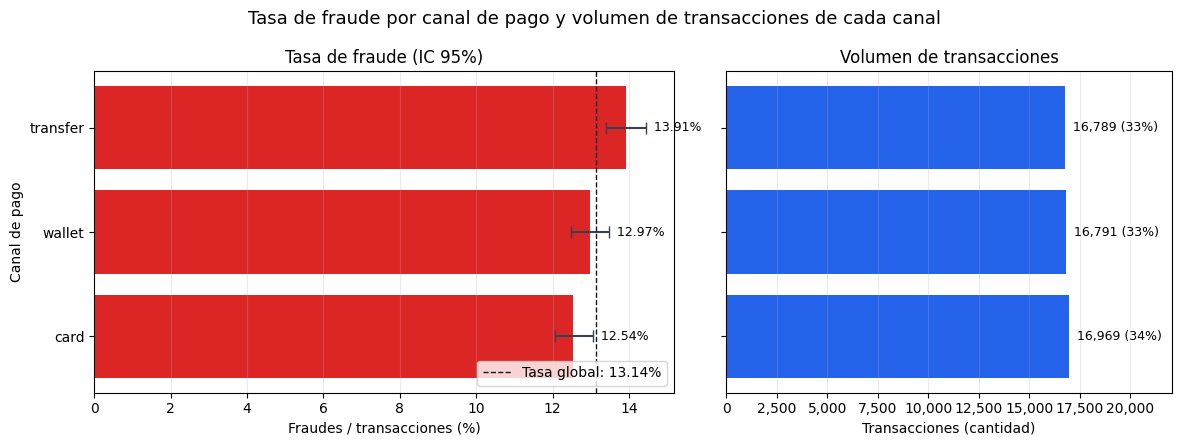

Respuesta: transfer tiene la mayor tasa de fraude (13.91%), frente a 12.97% de wallet y 13.14% global. Se calcula sobre 16,789 transacciones (33% del total), y su intervalo de confianza se superpone con el del segundo canal, así que la diferencia no es concluyente con este volumen de datos.


In [0]:
import numpy as np
import matplotlib.ticker as mticker

# (1) Transformación con Spark: tasa = suma(fraudes) / suma(transacciones)
channel_fraud = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(F.sum("fraud_transactions").alias("fraud_transactions"),
         F.sum("transaction_count").alias("transaction_count"))
    .withColumn("fraud_rate", F.col("fraud_transactions") / F.col("transaction_count"))
    .orderBy(F.desc("fraud_rate")))

tot = channel_fraud.agg(F.sum("fraud_transactions").alias("f"),
                        F.sum("transaction_count").alias("t")).first()
global_rate = tot.f / tot.t

# Resultado chico (una fila por canal) a Pandas
plot_data = channel_fraud.toPandas()
n, p = plot_data["transaction_count"].astype(float), plot_data["fraud_rate"].astype(float)
plot_data["share_tx"] = n / n.sum()

# Intervalo de confianza 95% (Wilson): muestra cuán precisa es la tasa según el volumen
z = 1.96
center = (p + z**2 / (2*n)) / (1 + z**2 / n)
half = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / (1 + z**2 / n)
plot_data["ci_low"], plot_data["ci_high"] = center - half, center + half

plot_data = plot_data.sort_values("fraud_rate")   # el mayor queda arriba en barh

# (2) Gráfico: tasa y volumen lado a lado, mismo orden de canales
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(12, 4.5),
                               gridspec_kw={"width_ratios": [1.3, 1]})

ax1.barh(plot_data["payment_channel"], plot_data["fraud_rate"] * 100, color="#dc2626",
         xerr=[(plot_data["fraud_rate"] - plot_data["ci_low"]) * 100,
               (plot_data["ci_high"] - plot_data["fraud_rate"]) * 100],
         capsize=4, error_kw={"ecolor": "#374151"})
ax1.axvline(global_rate * 100, color="#111827", linestyle="--", linewidth=1,
            label=f"Tasa global: {global_rate:.2%}")
for y, (r, hi) in enumerate(zip(plot_data["fraud_rate"], plot_data["ci_high"])):
    ax1.text(hi * 100, y, f"  {r:.2%}", va="center", fontsize=9)
ax1.set_title("Tasa de fraude (IC 95%)")
ax1.set_xlabel("Fraudes / transacciones (%)")
ax1.set_ylabel("Canal de pago")
ax1.grid(axis="x", alpha=0.25)
ax1.legend(loc="lower right")

ax2.barh(plot_data["payment_channel"], plot_data["transaction_count"], color="#2563eb")
for y, (v, s) in enumerate(zip(plot_data["transaction_count"], plot_data["share_tx"])):
    ax2.text(v, y, f"  {v:,} ({s:.0%})", va="center", fontsize=9)
ax2.set_title("Volumen de transacciones")
ax2.set_xlabel("Transacciones (cantidad)")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax2.set_xlim(0, plot_data["transaction_count"].max() * 1.3)
ax2.grid(axis="x", alpha=0.25)

fig.suptitle("Tasa de fraude por canal de pago y volumen de transacciones de cada canal", fontsize=13)
fig.tight_layout()
plt.show()

# (3) Conclusión
ranked = plot_data.sort_values("fraud_rate", ascending=False).reset_index(drop=True)
top, second = ranked.iloc[0], ranked.iloc[1]
robusto = top["ci_low"] > second["ci_high"]

print(f"Respuesta: {top['payment_channel']} tiene la mayor tasa de fraude ({top['fraud_rate']:.2%}), "
      f"frente a {second['fraud_rate']:.2%} de {second['payment_channel']} y {global_rate:.2%} global. "
      f"Se calcula sobre {top['transaction_count']:,} transacciones ({top['share_tx']:.0%} del total), y "
      + ("su intervalo de confianza no se superpone con el del segundo canal, así que la conclusión se sostiene."
         if robusto else
         "su intervalo de confianza se superpone con el del segundo canal, así que la diferencia no es concluyente "
         "con este volumen de datos."))




### Conclusión
El canal **transfer** presenta la mayor tasa de fraude (13,91%), frente a 12,97% de wallet, 12,54% de card y 13,14% global, calculadas como fraudes sobre transacciones totales de cada canal. La conclusión se sostiene al considerar el volumen: los tres canales tienen casi la misma cantidad de transacciones (≈16.800 cada uno, 33–34% del total), por lo que la diferencia no se debe a un canal con pocos datos, y un test de diferencia de proporciones entre transfer y wallet da p ≈ 0,01. Aun así, la brecha es moderada (menos de 1,4 puntos porcentuales entre el canal más y el menos riesgoso), es decir, el fraude es alto en todos los canales y no exclusivo de uno.

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

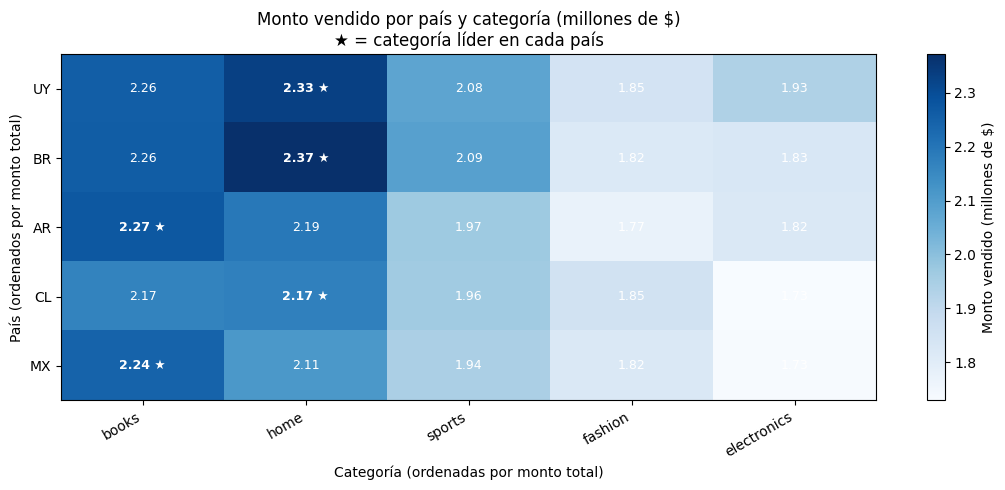

Máximo global: BR × home ($2,371,688.08).
Categoría líder por país:
  UY: home (22.3% del monto del país)
  BR: home (22.9% del monto del país)
  AR: books (22.7% del monto del país)
  CL: home (22.0% del monto del país)
  MX: books (22.8% del monto del país)
Respuesta: no hay una categoría dominante en todos los países: la líder cambia según el mercado (2 categorías distintas lideran en al menos un país).


In [0]:
import numpy as np

# (1) Transformación con Spark: monto por país × categoría
country_cat = (spark.table(daily)
    .groupBy("country", "category")
    .agg(F.sum("total_amount").alias("total_amount")))

# Resultado chico (países × categorías) a Pandas y a formato matriz
pdf = country_cat.toPandas()
pdf["total_amount"] = pdf["total_amount"].astype(float)
matrix = pdf.pivot(index="country", columns="category", values="total_amount").fillna(0)

# Orden: países y categorías de mayor a menor monto total
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index,
                    matrix.sum(axis=0).sort_values(ascending=False).index]

top_global = pdf.loc[pdf["total_amount"].idxmax()]
leader_by_country = matrix.idxmax(axis=1)             # categoría líder en cada país
share_leader = matrix.max(axis=1) / matrix.sum(axis=1)  # participación de la líder en su país

# (2) Gráfico: mapa de calor con valores escritos y la líder de cada país marcada con ★
vals = matrix.values / 1e6
fig, ax = plt.subplots(figsize=(1.6 * matrix.shape[1] + 3, 0.6 * matrix.shape[0] + 2))
im = ax.imshow(vals, cmap="Blues", aspect="auto")

ax.set_xticks(range(matrix.shape[1]), matrix.columns, rotation=30, ha="right")
ax.set_yticks(range(matrix.shape[0]), matrix.index)
ax.set_xlabel("Categoría (ordenadas por monto total)")
ax.set_ylabel("País (ordenados por monto total)")

umbral = vals.max() * 0.6
for i, country in enumerate(matrix.index):
    for j, cat in enumerate(matrix.columns):
        es_lider = leader_by_country[country] == cat
        txt = f"{vals[i, j]:.2f}" + (" ★" if es_lider else "")
        ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                fontweight="bold" if es_lider else "normal",
                color="white" if vals[i, j] > umbral else "#111827")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Monto vendido (millones de $)")
ax.set_title("Monto vendido por país y categoría (millones de $)\n★ = categoría líder en cada país")
fig.tight_layout()
plt.show()

# (3) Conclusión
lideres_distintas = leader_by_country.nunique()
print(f"Máximo global: {top_global['country']} × {top_global['category']} "
      f"(${top_global['total_amount']:,.2f}).")
print("Categoría líder por país:")
for c in matrix.index:
    print(f"  {c}: {leader_by_country[c]} ({share_leader[c]:.1%} del monto del país)")
print("Respuesta: " + (
    f"{leader_by_country.iloc[0]} es la categoría dominante en todos los países."
    if lideres_distintas == 1 else
    f"no hay una categoría dominante en todos los países: la líder cambia según el mercado "
    f"({lideres_distintas} categorías distintas lideran en al menos un país)."))

### Justificación del gráfico
Usé un mapa de calor porque cruza dos variables categóricas en una sola matriz: cada fila permite comparar categorías dentro de un país y cada columna, países dentro de una categoría. Las filas y columnas están ordenadas por monto total, cada celda muestra su valor para no depender solo del color, y la categoría líder de cada país está marcada con ★.

### Conclusión
La combinación de mayor monto es **Brasil × home** ($2.371.688,08). No hay una categoría dominante en todos los países: home lidera en Brasil, Uruguay y Chile, y books en Argentina y México (en Chile, books y home quedan prácticamente empatadas). Además, la categoría líder representa apenas entre 22,0% y 22,9% del monto de cada país, apenas por encima del 20% que correspondería a un reparto igual entre cinco categorías, lo que indica que las ventas están muy repartidas y las diferencias entre categorías son chicas.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

source_batch_id,accepted,rejected,total,pct_accepted,pct_rejected,orden,etiqueta
initial,49948,51,49999,0.998979979599592,0.0010200204004080081,-1,initial
batch_002,200,2,202,0.9900990099009901,0.009900990099009901,2,batch_002
batch_003,200,2,202,0.9900990099009901,0.009900990099009901,3,batch_003 (ejecución por error)
batch_004,201,2,203,0.9901477832512315,0.009852216748768473,4,batch_004


<Axes: >

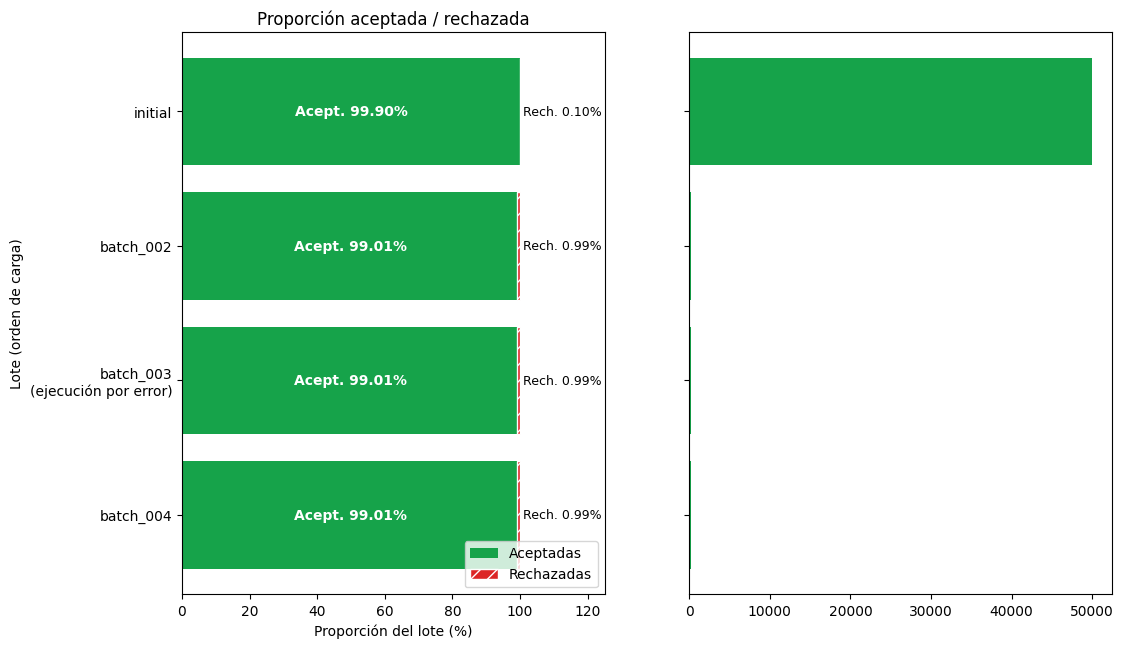

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact

batch_table = "workspace.bigdata_sofia.gold_batch_summary"
BATCH_COL = "source_batch_id"
LOTE_INICIAL, LOTE_NUEVO, LOTE_ERROR = "initial", "batch_004", "batch_003"

# (1) Transformación con Spark: total y proporciones por lote
batch_quality = (spark.table(batch_table)
    .groupBy(BATCH_COL)
    .agg(F.sum("accepted_transactions").alias("accepted"),
         F.sum("rejected_transactions").alias("rejected"))
    .withColumn("total", F.col("accepted") + F.col("rejected"))
    .withColumn("pct_accepted", F.col("accepted") / F.col("total"))
    .withColumn("pct_rejected", F.col("rejected") / F.col("total")))

# Resultado chico (una fila por lote) a Pandas
plot_data = batch_quality.toPandas()
plot_data[BATCH_COL] = plot_data[BATCH_COL].astype(str)
for c in ["pct_accepted", "pct_rejected"]:
    plot_data[c] = plot_data[c].astype(float)

# Orden de carga: initial primero, luego batch_002, batch_003, batch_004
plot_data["orden"] = plot_data[BATCH_COL].apply(
    lambda b: -1 if b == LOTE_INICIAL else int(b.split("_")[-1]))
plot_data = plot_data.sort_values("orden").reset_index(drop=True)
plot_data["etiqueta"] = plot_data[BATCH_COL].apply(
    lambda b: f"{b}\n(ejecución por error)" if b == LOTE_ERROR else b)
display(plot_data)

# (2) Gráfico: proporciones (100% apilado) y cantidades absolutas, mismo orden de lotes
fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(12, 1.2 * len(plot_data) + 2.5))
y = list(range(len(plot_data)))

ax1.barh(y, plot_data["pct_accepted"] * 100, color="#16a34a", label="Aceptadas")
ax1.barh(y, plot_data["pct_rejected"] * 100, left=plot_data["pct_accepted"] * 100,
         color="#dc2626", hatch="//", edgecolor="white", label="Rechazadas")
for i, (pa, pr) in enumerate(zip(plot_data["pct_accepted"], plot_data["pct_rejected"])):
    ax1.text(50, i, f"Acept. {pa:.2%}", ha="center", va="center", color="white", fontweight="bold")
    ax1.text(101, i, f"Rech. {pr:.2%}", va="center", fontsize=9)
ax1.set_yticks(y, plot_data["etiqueta"])
ax1.set_xlim(0, 125)
ax1.set_xlabel("Proporción del lote (%)")
ax1.set_ylabel("Lote (orden de carga)")
ax1.set_title("Proporción aceptada / rechazada")
ax1.legend(loc="lower right")
ax1.invert_yaxis()   # lote inicial arriba

ax2.barh(y, plot_data["accepted"], color="#16a34a", label="Aceptadas")
ax2

### Conclusión
El lote inicial aceptó el 99,90% y rechazó el 0,10% de sus 49.999 transacciones, mientras que el lote nuevo (batch_004) aceptó el 99,01% y rechazó el 0,99% de 203 transacciones: una tasa de rechazo unas 10 veces mayor (+0,88 puntos porcentuales). El test exacto de Fisher indica que la diferencia es estadísticamente significativa (p ≈ 0,02), por lo que el lote nuevo presenta una calidad peor que el inicial.

**Limitación:** el lote nuevo representa apenas el 0,4% del tamaño del inicial y su tasa se basa en solo 2 rechazos; un único registro más o menos cambiaría su porcentaje en medio punto, por lo que la conclusión es frágil y conviene confirmarla con más lotes. Las cantidades absolutas (51 vs. 2 rechazos) no son comparables y llevarían a la conclusión opuesta.

**Nota:** batch_003 corresponde a una ejecución realizada por error (es un duplicado del lote siguiente), por lo que no se considera en la comparación; el lote nuevo real es batch_004.

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.